#### Source Space Modelling

The source model in this project is a distributed dipole model with dipoles distributed uniformly on the subject specific inner cortical surface.

The following process can be found in `mindmap.source.make_DDM(...)`.

Note: Even if the sources are distributed on the inner cortical surface, we still apply a gray matter mask filter on the sources. The reason is that MNE uses the white pial surface from FreeSurfer to delimite the cortical surface, but some parts do not belong to the gray matter.

## Imports

In [1]:
import mindmap as mm
from mindmap.utils.sources import mask_sources
import nibabel as nib
import mne
from pathlib import Path

config = mm.io.read_config("../configurations/spike.yml")

## Data

In [2]:
# files
subject = "sub-pat09"
mm_dir  = Path(config["MM_DIR"])
fs_dir  = Path(config["FS_DIR"])
scale   = 4

T1      = fs_dir/subject/"mri"/"T1.mgz"
parc    = mm_dir/subject/"parc"/f"{subject}_multiConn{scale}-2-0.05_dparc.nii.gz"    # for mask
clut    = mm_dir/subject/"parc"/f"{subject}_multiConn{scale}-2-0.05_clut.txt"


# load
T1    = nib.load(T1)
torig = T1.header.get_vox2ras_tkr()
parc  = mm.utils.Parcellation(parc, clut)
df    = parc.get_clut()
ctx   = df[df["Label name"].str.startswith("ctx")]
mask  = parc.create_mask(ctx["#No."].values)

# parameters
constraint = {"type":"surf", "mask":mask}
spacing    = 7
n_jobs     = 10

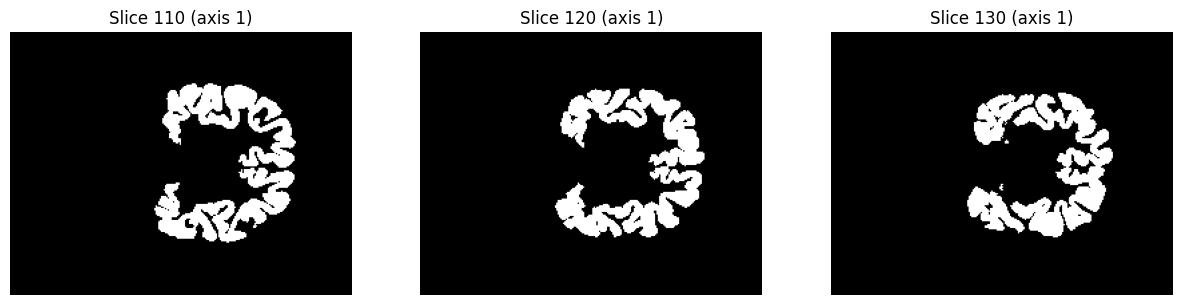

In [3]:
mm.viz.show_slices(mask, [110, 120, 130], axis=1)

## Generate source space
Run time: 1 min (with n_jobs=10) <br>
Generate source space using python-MNE.
- Surface sources are positioned along the pial surface. The pial surface passes through white matter region at the center of the brain.
- Volumetric sources are placed uniformly inside a cube rougthly the size of the brain.
To eliminate sources not in gray matter we mask sources with the gray matter mask.

In [4]:

if constraint["type"] == "surf": # (1 min)
    # Constrained on inner cortical surface.
    sources = mne.setup_source_space(
        subject=subject,
        spacing=spacing,
        surface="white",
        add_dist=True,      # geodesic distances between sources
        subjects_dir=fs_dir,
        n_jobs=n_jobs
    )

elif constraint["type"] == "vol":
    # Unconstrained
    sources = mne.setup_volume_source_space(
        subject=subject,
        pos=spacing,
        subjects_dir=fs_dir
    )
    
# gray matter constraint 
if constraint["mask"] is not None:
    sources = mask_sources(sources, constraint["mask"], mask.affine)

Setting up the source space with the following parameters:

SUBJECTS_DIR = /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1
Subject      = sub-pat09
Surface      = white
Approximate spacing 7 mm

>>> 1. Creating the source space...

Loading /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/surf/lh.white...
Mapping lh sub-pat09 -> spacing (7) ...
    Triangle neighbors and vertex normals...
    Vertex neighbors...
    Decimating...
loaded lh.white 2727/111268 selected to source space (spacing = 7)

Loading /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/surf/rh.white...
Mapping rh sub-pat09 -> spacing (7) ...
    Triangle neighbors and vertex normals...
    Vertex neighbors...
    Decimating...
loaded rh.white 2936/120260 selected to source space (spacing = 7)

Calculating source space distances (limit=inf mm)...


[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done   4 out of  10 | elapsed:   17.1s remaining:   25.6s
[Parallel(n_jobs=10)]: Done   7 out of  10 | elapsed:   17.8s remaining:    7.6s
[Parallel(n_jobs=10)]: Done  10 out of  10 | elapsed:   18.2s finished
[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done   4 out of  10 | elapsed:   19.0s remaining:   28.5s
[Parallel(n_jobs=10)]: Done   7 out of  10 | elapsed:   19.4s remaining:    8.3s
[Parallel(n_jobs=10)]: Done  10 out of  10 | elapsed:   19.8s finished


    Computing patch statistics...
    Patch information added...
    Computing patch statistics...
    Patch information added...
You are now one step closer to computing the gain matrix


In [5]:
for src in sources:
    print(f"Type: {src["type"]}")
    print(f"Number of used sources: {src["nuse"]}\n")

Type: surf
Number of used sources: 2495

Type: surf
Number of used sources: 2705



In [6]:
%matplotlib qt

sources.plot(subjects_dir = fs_dir)

Using pyvistaqt 3d backend.

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


## Save Sources

In [7]:
# save source space
folder = mm_dir/subject/"src"

if folder.exists() == False:
        folder.mkdir(parents=True)

print(f"saving sources for patient: {subject}")
sources.save(folder/f"{subject}_ddm-{constraint["type"]}-{spacing}-src.fif", overwrite=True)

saving sources for patient: sub-pat09
Overwriting existing file.
    Write a source space...
    [done]
    Write a source space...
    [done]
    2 source spaces written
